# MLP — Rede neural do T2

Este notebook fica junto de `mlp.py`, como nos algoritmos do T1. Aqui vamos executar a rede por partes: definir a classe, criar os pesos, passar um tabuleiro e conferir as saídas.

A MLP escolhe onde jogar. O treinamento dos pesos fica no notebook do algoritmo genético. Não usamos backpropagation.

No VS Code, escolha o kernel da `.venv` e execute as células na ordem. As dependências estão em `t2/apoio/requirements-notebook.txt`, na raiz do projeto.

In [1]:
from pathlib import Path
import sys
import json
from html import escape
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# Localiza o projeto mesmo abrindo o notebook pela pasta do algoritmo.
pasta_atual = Path.cwd().resolve()
raiz = next((p for p in [pasta_atual, *pasta_atual.parents] if (p / "t2" / "app.py").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Abra o notebook dentro do repositório.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from t2.apoio.treinamento import evaluate
import csv
pasta_algoritmo = raiz / "t2" / "algoritmos" / "mlp"

def salvar_grafico(figura, nome):
    # Salva uma cópia do gráfico junto do algoritmo.
    figura.savefig(pasta_algoritmo / nome, dpi=150, bbox_inches="tight")

def salvar_csv(nome, linhas):
    with (pasta_algoritmo / nome).open("w", newline="", encoding="utf-8") as arquivo:
        escritor = csv.DictWriter(arquivo, fieldnames=list(linhas[0]))
        escritor.writeheader()
        escritor.writerows(linhas)


In [2]:
def mostrar_tabela(colunas, linhas):
    cabecalho = "".join(f"<th style='padding:8px;text-align:left'>{escape(str(c))}</th>" for c in colunas)
    corpo = "".join("<tr>" + "".join(f"<td style='padding:8px;border-top:1px solid #ddd'>{escape(str(v))}</td>" for v in linha) + "</tr>" for linha in linhas)
    display(HTML(f"<table><thead><tr>{cabecalho}</tr></thead><tbody>{corpo}</tbody></table>"))

## Implementação da rede

A classe abaixo tem o mesmo código de `mlp.py`. São 9 entradas, uma camada oculta com tanh e 9 saídas lineares. Os bias também ficam no cromossomo.

In [3]:
class Network:
    """
    São 9 entradas, H neurônios ocultos com tanh e 9 saídas lineares.
    Cada saída representa uma casa. Os pesos e os bias das duas camadas
    ficam juntos no cromossomo.
    """
    def __init__(self, weights, hidden=9):
        self.hidden = hidden
        self.weights = np.asarray(weights, dtype=float)
        if self.weights.shape != (self.size(hidden),) or not np.isfinite(self.weights).all():
            raise ValueError('Cromossomo incompatível com a topologia.')
        cut = 9 * hidden
        self.w1 = self.weights[:cut].reshape(9, hidden)
        self.b1 = self.weights[cut:cut+hidden]
        cut += hidden
        self.w2 = self.weights[cut:cut+hidden*9].reshape(hidden, 9)
        self.b2 = self.weights[-9:]

    @staticmethod
    def size(hidden):
        return 9*hidden + hidden + hidden*9 + 9

    def forward(self, board, player):
        # Lemos o tabuleiro pelo lado da rede, tanto quando ela é X quanto O.
        # A peça dela vale 1, a do adversário -1 e a casa vazia 0.
        inputs = np.asarray(board, dtype=float) * player
        activation = np.tanh(inputs @ self.w1 + self.b1)
        return activation @ self.w2 + self.b2

    def choose(self, board, player):
        outputs = self.forward(board, player)
        ranking = np.argsort(-outputs, kind='stable')
        raw = int(ranking[0])
        # Se a primeira escolha estiver ocupada, ela continua contando como erro.
        # A partida segue usando a próxima casa livre no ranking da rede.
        move = next(int(i) for i in ranking if board[i] == 0)
        return raw, move, outputs.tolist()

## Pesos iniciais

Vamos criar uma rede com pesos sorteados entre -1 e 1. Com a camada oculta de 9 neurônios, são 180 parâmetros.

In [4]:
ocultos = 9
semente = 42
rng = np.random.default_rng(semente)
pesos = rng.uniform(-1, 1, Network.size(ocultos))
rede_inicial = Network(pesos, ocultos)
print("Parâmetros:", len(pesos))
mostrar_tabela(["Camada", "Formato"], [
    ["W1", rede_inicial.w1.shape], ["b1", rede_inicial.b1.shape],
    ["W2", rede_inicial.w2.shape], ["b2", rede_inicial.b2.shape],
])

Parâmetros: 180


Camada,Formato
W1,"(9, 9)"
b1,"(9,)"
W2,"(9, 9)"
b2,"(9,)"


## Propagação de um tabuleiro

A própria peça vale 1, a do adversário vale -1 e uma casa vazia vale 0. O parâmetro `jogador` indica de quem é a vez. A maior saída é a escolha original da rede, que ainda pode ser uma casa ocupada.

In [5]:
tabuleiro = [1, -1, 0, 0, 1, 0, -1, 0, 0]
jogador = 1
original, executada, saidas = rede_inicial.choose(tabuleiro, jogador)
mostrar_tabela(["Casa", "Ocupação", "Saída"], [[i+1, tabuleiro[i], saidas[i]] for i in range(9)])
print("Escolha original:", original+1)
print("Casa executada:", executada+1)
print("Escolha original ocupada:", tabuleiro[original] != 0)

Casa,Ocupação,Saída
1,1,-0.013207284245494222
2,-1,-0.15415573612077937
3,0,1.265278819457143
4,0,0.30609977075546513
5,1,-0.45117898187272754
6,0,-1.2954745817445912
7,-1,1.7310073711822715
8,0,3.8606945466289146
9,0,-0.788678324936106


Escolha original: 8
Casa executada: 8
Escolha original ocupada: False


## Rede com os pesos do experimento

Agora carregamos os pesos que o AG encontrou. A estrutura da MLP é a mesma, o que muda são os valores do cromossomo. Não estamos treinando novamente nesta célula.

In [6]:
salva = json.loads((raiz / "t2" / "algoritmos" / "genetico" / "rede-t2.json").read_text())
rede_treinada = Network(salva["weights"], salva["hidden"])
original, executada, saidas = rede_treinada.choose(tabuleiro, jogador)
mostrar_tabela(["Casa", "Saída da rede treinada"], [[i+1, valor] for i, valor in enumerate(saidas)])
print("Escolha original:", original+1)
print("Casa executada:", executada+1)

Casa,Saída da rede treinada
1,-1.1729558979419061
2,-0.9316089431147393
3,2.836527361197036
4,-1.2969699638694023
5,2.529485725789841
6,-1.2038554412049924
7,-0.03786083984451033
8,-1.961206761160276
9,-0.34172738125334157


Escolha original: 3
Casa executada: 3


## Tabuleiro e saídas da rede

O mesmo tabuleiro é apresentado às duas redes. Os escores não são probabilidades. A barra vermelha identifica uma casa ocupada, enquanto a linha pontilhada marca a primeira escolha de cada rede. Assim dá para perceber quando a maior saída aponta para uma posição inválida.

A rede inicial aqui é a rede aleatória criada neste notebook. Ela não é a melhor da primeira geração do relatório, que já tinha passado por seleção.

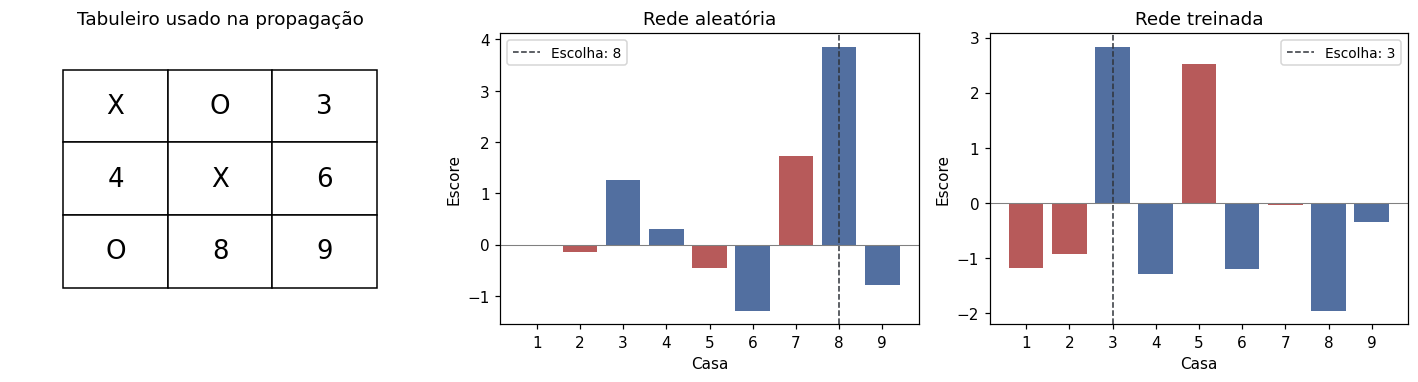

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6))
tabela = eixos[0].table(
    cellText=[["X" if v == 1 else "O" if v == -1 else str(i+1) for i, v in enumerate(tabuleiro)][j:j+3] for j in (0, 3, 6)],
    loc="center", cellLoc="center", colWidths=[0.25]*3,
)
for celula in tabela.get_celld().values():
    celula.set_height(0.25)
    celula.set_fontsize(17)
eixos[0].set_title("Tabuleiro usado na propagação")
eixos[0].axis("off")
for eixo, rede, titulo in zip(eixos[1:], [rede_inicial, rede_treinada], ["Rede aleatória", "Rede treinada"]):
    escores = rede.forward(tabuleiro, jogador)
    escolha = int(np.argmax(escores))
    eixo.bar(range(1, 10), escores, color=["#b75a5a" if v else "#526fa0" for v in tabuleiro])
    eixo.axvline(escolha+1, color="#30343a", linestyle="--", linewidth=1, label=f"Escolha: {escolha+1}")
    eixo.axhline(0, color="gray", linewidth=0.7)
    eixo.set(title=titulo, xlabel="Casa", ylabel="Escore", xticks=range(1, 10))
    eixo.legend(fontsize=9)
fig.tight_layout()
salvar_grafico(fig, "mlp_saidas.png")
plt.show()
plt.close(fig)

## Pesos das duas camadas

As cores mostram o valor das conexões. Usamos a mesma escala nos dois mapas de cada rede, entre -1 e 1, para não dar a impressão de uma diferença só por causa da escala. Os bias não entram nestes mapas, mas estão no cromossomo e aparecem na distribuição seguinte.

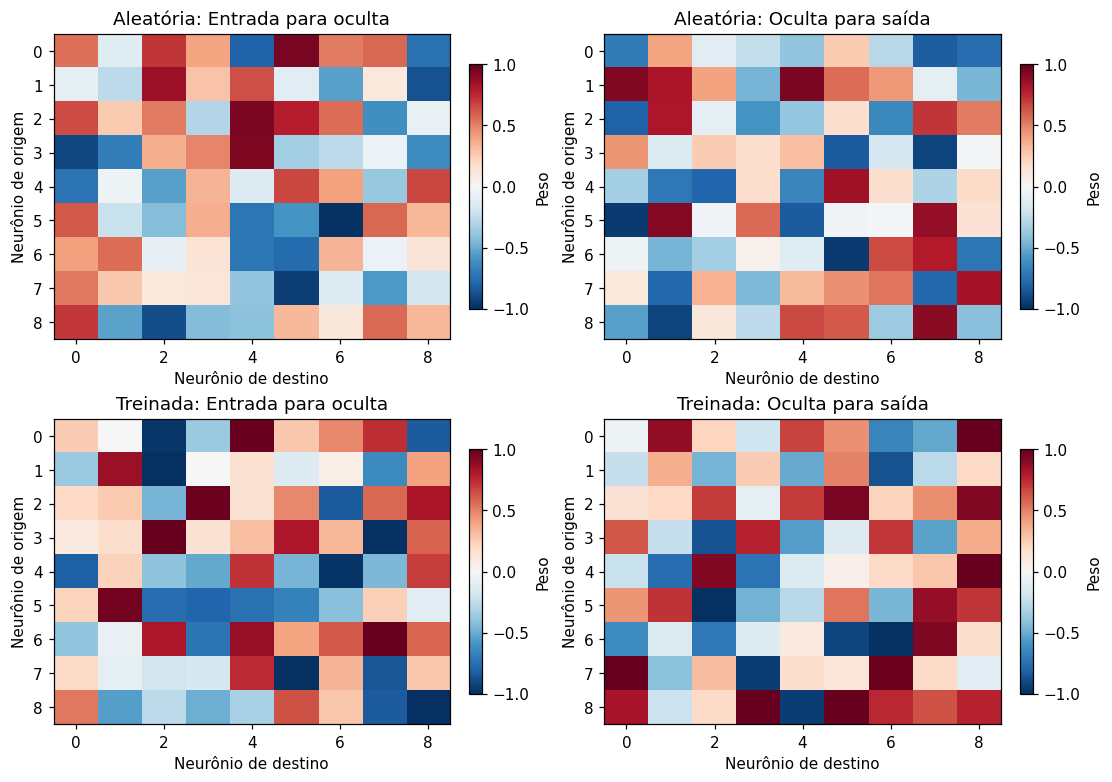

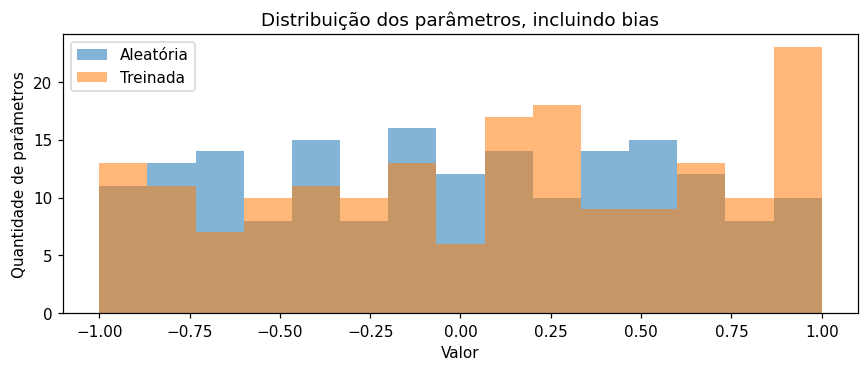

In [8]:
fig, eixos = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
for linha, rede, nome in zip(eixos, [rede_inicial, rede_treinada], ["Aleatória", "Treinada"]):
    for eixo, matriz, camada in zip(linha, [rede.w1, rede.w2], ["Entrada para oculta", "Oculta para saída"]):
        mapa = eixo.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
        eixo.set(title=f"{nome}: {camada}", xlabel="Neurônio de destino", ylabel="Neurônio de origem")
        fig.colorbar(mapa, ax=eixo, label="Peso", shrink=0.8)
salvar_grafico(fig, "mlp_pesos.png")
plt.show()
plt.close(fig)

fig, eixo = plt.subplots(figsize=(8, 3.5))
for rede, nome in [(rede_inicial, "Aleatória"), (rede_treinada, "Treinada")]:
    eixo.hist(rede.weights, bins=np.linspace(-1, 1, 16), alpha=0.55, label=nome)
eixo.set(title="Distribuição dos parâmetros, incluindo bias", xlabel="Valor", ylabel="Quantidade de parâmetros")
eixo.legend()
fig.tight_layout()
salvar_grafico(fig, "mlp_distribuicao_pesos.png")
plt.show()
plt.close(fig)

## Avaliação das escolhas

Usamos o teste reservado para olhar as decisões da rede carregada. A acurácia verifica se a escolha original está entre as ações ótimas do Minimax. A recuperação de uma posição inválida não transforma essa escolha em acerto.

In [9]:
resultados = {
    "Médio": evaluate(rede_treinada, 100, False, 1000000, True),
    "Difícil": evaluate(rede_treinada, 0, True, 2000000, True),
}
mostrar_tabela(["Modo", "Vitórias", "Empates", "Derrotas", "Inválidas", "Acurácia"], [
    [modo, r["vitoria"], r["empate"], r["derrota"], r["invalid"], f'{100*r["accuracy"]:.1f}%']
    for modo, r in resultados.items()
])

Modo,Vitórias,Empates,Derrotas,Inválidas,Acurácia
Médio,64,21,15,62,77.9%
Difícil,0,2,0,1,88.9%


## Comparação no teste reservado

A tabela anterior mostra os números da rede treinada. Aqui colocamos ao lado a rede aleatória deste notebook, usando as mesmas partidas de teste. A comparação é das duas redes avaliadas, não de todas as redes da população.

A acurácia de decisões e a proporção de escolhas válidas são medidas diferentes. Uma escolha pode estar em uma casa livre e mesmo assim não ser uma jogada ótima.

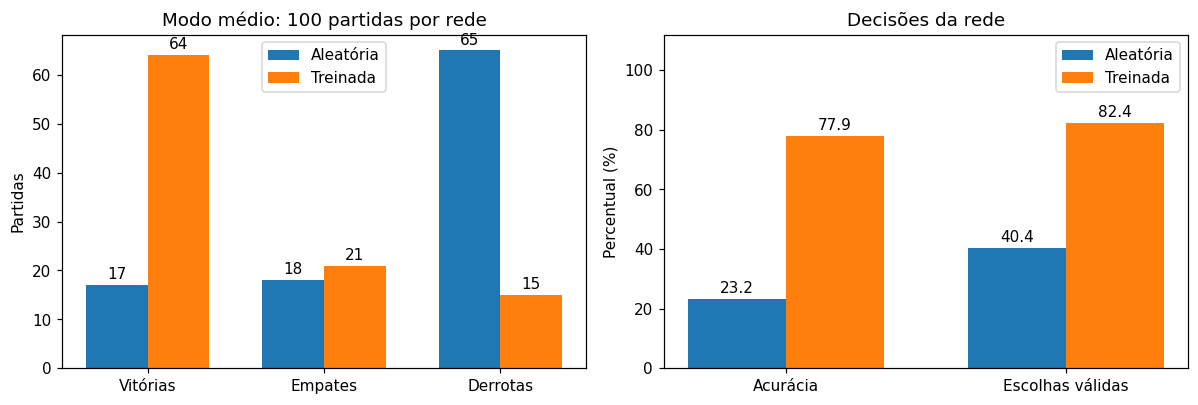

In [10]:
comparacao_mlp = {
    "Aleatória": evaluate(rede_inicial, 100, False, 1000000, True),
    "Treinada": resultados["Médio"],
}
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(3)
for i, (nome, r) in enumerate(comparacao_mlp.items()):
    barras = eixos[0].bar(x+(i-0.5)*0.35, [r["vitoria"], r["empate"], r["derrota"]], 0.35, label=nome)
    eixos[0].bar_label(barras, padding=2)
eixos[0].set(title="Modo médio: 100 partidas por rede", ylabel="Partidas", xticks=x, xticklabels=["Vitórias", "Empates", "Derrotas"])
eixos[0].legend()
x = np.arange(2)
for i, (nome, r) in enumerate(comparacao_mlp.items()):
    barras = eixos[1].bar(x+(i-0.5)*0.35, [100*r["accuracy"], 100*r["valid_rate"]], 0.35, label=nome)
    eixos[1].bar_label(barras, fmt="%.1f", padding=2)
eixos[1].set(title="Decisões da rede", ylabel="Percentual (%)", ylim=(0, 112), xticks=x, xticklabels=["Acurácia", "Escolhas válidas"])
eixos[1].legend()
fig.tight_layout()
salvar_grafico(fig, "mlp_comparativo.png")
plt.show()
plt.close(fig)

## Relação com os outros algoritmos

A rede só calcula a jogada com os pesos que recebeu. Para acompanhar como esses pesos são escolhidos, abra [genetico.ipynb](../genetico/genetico.ipynb). O adversário usado na avaliação está em [minimax.ipynb](../minimax/minimax.ipynb).

Os arquivos `.py` continuam sendo usados pelo Flask. Se alterar a implementação no notebook, essa alteração não muda automaticamente o arquivo `.py`.

## Arquivos na pasta do algoritmo

Os gráficos mostrados acima também são salvos em PNG nesta pasta. Os números vão para arquivos CSV, junto do código e do notebook, como no T1. Rodar as células novamente atualiza esses arquivos com a execução atual.


In [11]:
salvar_csv("mlp_resultados_teste.csv", [
    {"rede": "Treinada", "modo": modo, **r} for modo, r in resultados.items()
] + [{"rede": "Aleatória", "modo": "Médio", **comparacao_mlp["Aleatória"]}])
salvar_csv("mlp_saidas.csv", [
    {"casa": i+1, "ocupacao": tabuleiro[i],
     "escore_aleatoria": float(rede_inicial.forward(tabuleiro, jogador)[i]),
     "escore_treinada": float(rede_treinada.forward(tabuleiro, jogador)[i])}
    for i in range(9)
])
salvar_csv("mlp_pesos.csv", [
    {"parametro": i+1, "aleatoria": float(a), "treinada": float(b)}
    for i, (a, b) in enumerate(zip(rede_inicial.weights, rede_treinada.weights))
])
print("Arquivos PNG e CSV em:", pasta_algoritmo.relative_to(raiz))


Arquivos PNG e CSV em: t2/algoritmos/mlp
